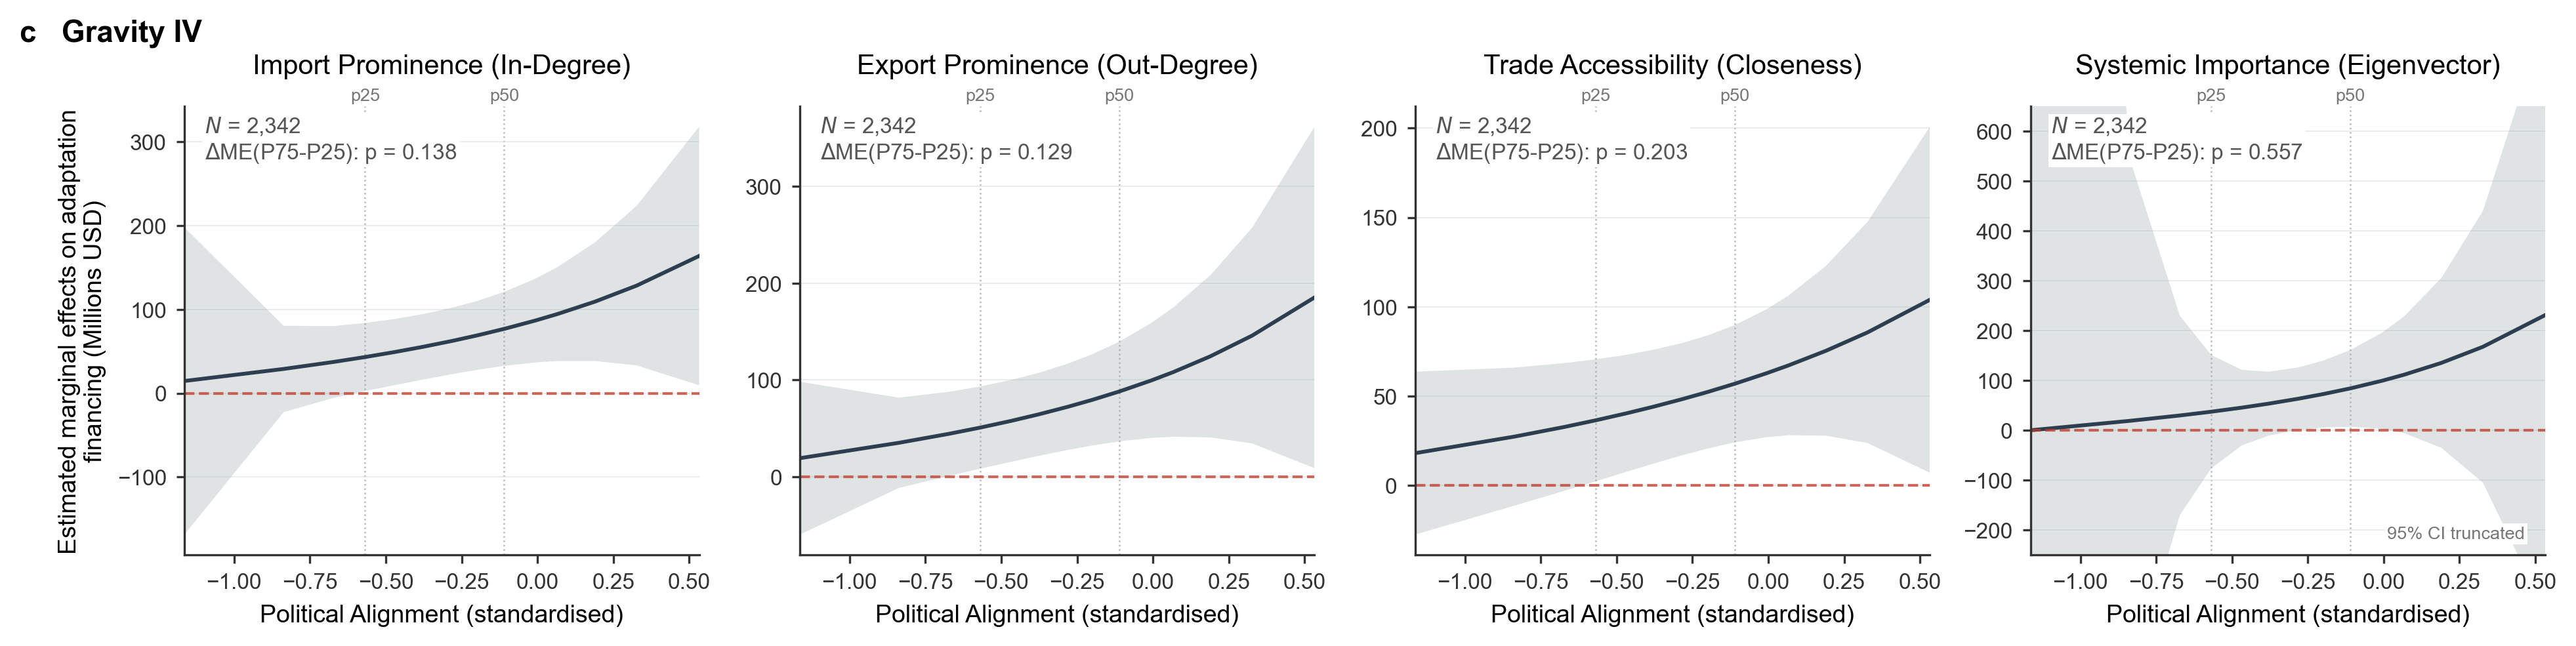

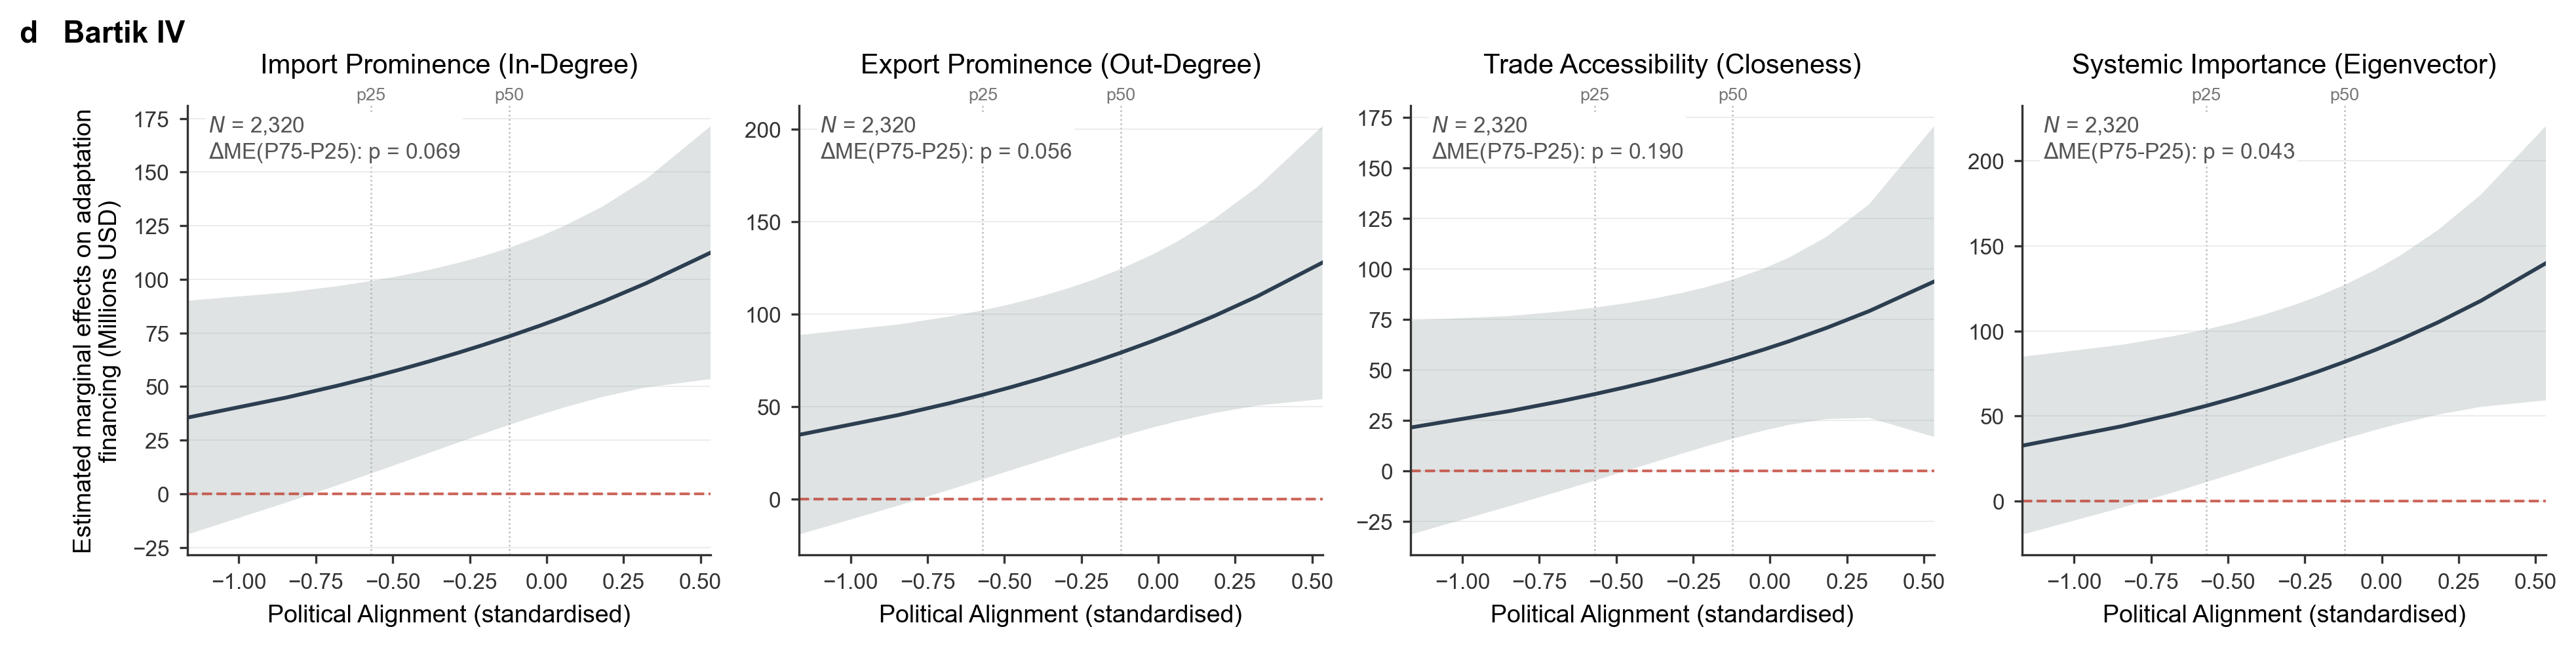

In [1]:
# Fig. 6c-d as separate files: marginal effect over political alignment (P10-P75,
# standardised), gravity IV (c) and Bartik IV (d); annotated test ME(P75)-ME(P25).
# Each file is one row of Fig. 6, drawn with the same draw_row() and settings as Fig6_combined.
# The earlier version (MEs at a few percentiles) is in output/backup_fig6_pointwise_20261025/.
# Reads  : curve tables and draws from modules 06c / 07c
# Writes : output/figures/Fig.6_marginal_effects_idealpoint_GravityIV.{pdf,png}, Fig.6_marginal_effects_idealpoint_BartikIV.{pdf,png}
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES = "../output/tables"
FIGURES = "../output/figures"
BOOTDRAWS = "../output/bootstrap"
TRIM = 0.0  # share of replicates dropped in each tail; 0 = plain bootstrap SE (1% until 2026-10-26)

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.8
})

centralities = ['in_degree', 'out_degree', 'closeness', 'eigenvector']
titles = {
    'in_degree': 'Import Prominence (In-Degree)',
    'out_degree': 'Export Prominence (Out-Degree)',
    'closeness': 'Trade Accessibility (Closeness)',
    'eigenvector': 'Systemic Importance (Eigenvector)'
}

# One row per panel. key/mod: curve table and draw files; col: column identifying the
# reference points; keep: rows plotted; diff: annotated test (high, low); marks: dotted lines
# ylim (optional): fixed y-range per centrality; the CI band is clipped and flagged
PANELS = [
    dict(letter='a', iv_label='Gravity IV', iv='gravity', suffix='', key='disaster', mod='mod06c',
         col='label', keep=lambda d: d, diff=('P95', 'P50'), marks=['P75', 'P90'],
         xlabel='Disaster impact severity (standardised)'),
    dict(letter='b', iv_label='Bartik IV', iv='bartik', suffix='_Bartik', key='disaster', mod='mod06c',
         col='label', keep=lambda d: d, diff=('P95', 'P50'), marks=['P75', 'P90'],
         xlabel='Disaster impact severity (standardised)'),
    dict(letter='c', iv_label='Gravity IV', iv='gravity', suffix='', key='idealpoint', mod='mod07c',
         col='pct', keep=lambda d: d[d.pct <= 75], diff=(75, 25), marks=[25, 50],
         xlabel='Political Alignment (standardised)',
         # Weak first stage for eigenvector x alignment under the gravity IV (F = 15.7):
         # a few replicates diverge at low alignment, so fix the axis and clip the band
         ylim={'eigenvector': (-250, 650)}),
    dict(letter='d', iv_label='Bartik IV', iv='bartik', suffix='_Bartik', key='idealpoint', mod='mod07c',
         col='pct', keep=lambda d: d[d.pct <= 75], diff=(75, 25), marks=[25, 50],
         xlabel='Political Alignment (standardised)'),
]


def trimmed_se(x, trim=TRIM):
    """Bootstrap SD after dropping the top and bottom `trim` share of replicates."""
    x = x.dropna()
    lo, hi = x.quantile([trim, 1 - trim])
    return x[x.between(lo, hi)].std()


def plabel(p):
    return f"P{p}" if isinstance(p, int) else p


def draw_row(axrow, P):
    """Draw one panel of Fig. 6 (four centralities) on a row of four axes."""
    curve = pd.read_csv(f"{TABLES}/Moderation_{P['key']}_Curve_CF{P['suffix']}.csv")
    for j, v in enumerate(centralities):
        ax = axrow[j]
        d = curve[curve.centrality == v].reset_index(drop=True)
        draws = pd.read_stata(f"{BOOTDRAWS}/{P['mod']}_{P['iv']}_curve_{v}.dta")
        # Draw columns are in the same order as the table rows (grid order)
        d['se'] = [trimmed_se(draws[c]) for c in draws.columns]

        # Difference in marginal effects (Fig. 6 test), from the same replicates
        hi = d.index[d[P['col']] == P['diff'][0]][0]
        lo = d.index[d[P['col']] == P['diff'][1]][0]
        diff = d.me[hi] - d.me[lo]
        p = math.erfc(abs(diff / trimmed_se(draws.iloc[:, hi] - draws.iloc[:, lo])) / math.sqrt(2))
        ptxt = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

        d = P['keep'](d).sort_values('mod_value')
        xv, me = d.mod_value.to_numpy(), d.me.to_numpy()
        lb, ub = me - 1.96 * d.se.to_numpy(), me + 1.96 * d.se.to_numpy()

        ax.fill_between(xv, lb, ub, color='#95A5A6', alpha=0.30, edgecolor='none')
        ax.plot(xv, me, color='#2C3E50', linewidth=1.4)
        ax.axhline(0, color='#C0392B', linestyle='--', linewidth=1, alpha=0.75)

        # Reference percentiles: dotted lines, labelled on a top axis
        xps = [d.loc[d[P['col']] == m, 'mod_value'].iloc[0] for m in P['marks']]
        for xp in xps:
            ax.axvline(xp, color='#BBBBBB', linewidth=0.6, linestyle=':', zorder=0)
        top = ax.secondary_xaxis('top')
        top.set_xticks(xps, [plabel(m).lower() for m in P['marks']])
        top.tick_params(length=0, labelsize=6.5, labelcolor='#777777', pad=1)
        top.spines['top'].set_visible(False)

        dtxt = f"{plabel(P['diff'][0])}-{plabel(P['diff'][1])}"
        ax.text(0.04, 0.98, f"$\\mathit{{N}}$ = {int(d.nobs.iloc[0]):,}\n$\\Delta$ME({dtxt}): {ptxt}",
                transform=ax.transAxes, fontsize=8, color='#555555', va='top', ha='left',
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
        ax.set_title(titles[v], pad=12)
        ax.set_xlim(xv.min(), xv.max())
        ylim = P.get('ylim', {}).get(v)
        if ylim is not None:
            ax.set_ylim(*ylim)
            if lb.min() < ylim[0] or ub.max() > ylim[1]:
                ax.text(0.96, 0.03, '95% CI truncated', transform=ax.transAxes, fontsize=6.5,
                        color='#777777', va='bottom', ha='right',
                        bbox=dict(facecolor='white', edgecolor='none', pad=1))
        for s in ['top', 'right']:
            ax.spines[s].set_visible(False)
        for s in ['left', 'bottom']:
            ax.spines[s].set_color('#333333')
        ax.tick_params(colors='#333333', direction='out', length=3, width=0.8)
        ax.set_axisbelow(True)
        ax.grid(axis='y', linestyle='-', color='#E0E0E0', alpha=0.6, linewidth=0.5)
        if j == 0:
            ax.set_ylabel('Estimated marginal effects on adaptation\nfinancing (Millions USD)')
        ax.set_xlabel(P['xlabel'])

    axrow[0].text(-0.32, 1.13, f"{P['letter']}   {P['iv_label']}", transform=axrow[0].transAxes,
                      fontsize=11, fontweight='bold', va='bottom', ha='left')


for P, out in zip(PANELS[2:], ['Fig.6_marginal_effects_idealpoint_GravityIV', 'Fig.6_marginal_effects_idealpoint_BartikIV']):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), dpi=300)
    draw_row(axes, P)
    plt.tight_layout()
    plt.savefig(f"{FIGURES}/{out}.pdf", bbox_inches='tight', transparent=True)
    plt.savefig(f"{FIGURES}/{out}.png", dpi=600, bbox_inches='tight')
    plt.show()
